<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/3%20-%20Regress%C3%A3o%20Log%C3%ADstica/3.2_regressao_softmax_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 3.2 — Regressão softmax no MNIST

## Objetivos

- Aplicar a mesma regressão softmax do notebook 3.1 ao reconhecimento de dígitos manuscritos (MNIST).
- Transformar cada imagem 28×28 num vetor de 784 atributos com `view(-1, 28*28)`.
- Treinar `nn.Linear(784, 10)` com 1000 amostras e acompanhar custo e acurácia no treino e na validação.
- Interpretar os pesos de cada classe como imagens 28×28.

## O problema

Dada a imagem de um dígito escrito à mão, qual é o dígito (0 a 9)?

- **Entrada**: uma imagem em tons de cinza de 28 × 28 pixels, ou seja, 784 atributos (no 3.1 eram 2).
- **Saída esperada**: o índice da classe correta, de 0 a 9 (no 3.1 eram 3 classes).
- **Modelo**: o mesmo do 3.1, uma camada linear com uma saída (logit) por classe: $z = Wx + b$, com $W$ de shape (10, 784) e $b$ de shape (10,).
- **Função de custo**: a mesma cross-entropy, `nn.CrossEntropyLoss`, que recebe os logits.

O MNIST tem 60 mil imagens de treino e 10 mil de teste. Aqui usamos só 1000 imagens de treino, todas de uma vez em cada época (batch completo). O notebook 3.4 usa as 60 mil com mini-batches. Como o modelo é linear, cada classe tem um vetor de 784 pesos que pode ser visto como uma imagem 28 × 28: no final vamos interpretar o que o modelo aprendeu.

## Importação das bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F

import torchvision
from torchvision.datasets import MNIST

torch.manual_seed(0)
np.random.seed(0)

## Dados: carregamento do MNIST

`torchvision.datasets.MNIST` baixa os arquivos para `./data` na primeira execução (o mesmo diretório do notebook 3.4) e os reutiliza depois. Os atributos `.data` e `.targets` do dataset contêm todas as imagens (tensor `uint8`) e todos os rótulos. Eles não têm relação com o antigo `tensor.data` do PyTorch, que não usamos mais.

In [2]:
mnist_train = MNIST(root='./data', train=True, download=True)
mnist_test = MNIST(root='./data', train=False, download=True)

x_train, y_train = mnist_train.data, mnist_train.targets

print("Amostras de treinamento:", x_train.size(0))

print("\nDimensões dos dados das imagens:   ", x_train.size())
print("Valores mínimo e máximo dos pixels:", torch.min(x_train), torch.max(x_train))
print("Tipo dos dados das imagens:        ", type(x_train), x_train.dtype)
print("Tipo das classes das imagens:      ", type(y_train), y_train.dtype)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.83MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 153kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.2MB/s]

Amostras de treinamento: 60000

Dimensões dos dados das imagens:    torch.Size([60000, 28, 28])
Valores mínimo e máximo dos pixels: tensor(0, dtype=torch.uint8) tensor(255, dtype=torch.uint8)
Tipo dos dados das imagens:         <class 'torch.Tensor'> torch.uint8
Tipo das classes das imagens:       <class 'torch.Tensor'> torch.int64


### Normalização e seleção dos dados de treinamento

Os pixels vão de 0 a 255 (`uint8`). Convertemos para `float32` e dividimos por 255, para que fiquem entre 0 e 1. Neste exemplo utilizaremos apenas as 1000 primeiras amostras de treinamento.

In [3]:
x_train = x_train.float() / 255.

n_samples_train = 1000
x_train = x_train[:n_samples_train]
y_train = y_train[:n_samples_train]

print("Amostras de treinamento:", x_train.size(0))

print("\nDimensões dos dados das imagens:   ", x_train.size())
print("Valores mínimo e máximo dos pixels:", torch.min(x_train), torch.max(x_train))
print("Tipo dos dados das imagens:        ", x_train.dtype)
print("Tipo das classes das imagens:      ", y_train.dtype)

Amostras de treinamento: 1000

Dimensões dos dados das imagens:    torch.Size([1000, 28, 28])
Valores mínimo e máximo dos pixels: tensor(0.) tensor(1.)
Tipo dos dados das imagens:         torch.float32
Tipo das classes das imagens:       torch.int64


### Normalização e seleção dos dados de validação

Para medir o desempenho em imagens que o modelo não usou no treinamento, separamos 1000 imagens do conjunto de teste do MNIST como conjunto de validação, com a mesma normalização.

In [4]:
x_val, y_val = mnist_test.data, mnist_test.targets
x_val = x_val.float() / 255.

n_samples_val = 1000
x_val = x_val[:n_samples_val]
y_val = y_val[:n_samples_val]

print("Amostras de validação:", x_val.size(0))
print("Dimensões dos dados das imagens de validação:", x_val.size())
print("Distribuição das classes no treino:   ", torch.bincount(y_train).tolist())
print("Distribuição das classes na validação:", torch.bincount(y_val).tolist())

Amostras de validação: 1000
Dimensões dos dados das imagens de validação: torch.Size([1000, 28, 28])
Distribuição das classes no treino:    [97, 116, 99, 93, 105, 92, 94, 117, 87, 100]
Distribuição das classes na validação: [85, 126, 116, 107, 110, 87, 87, 99, 89, 94]


### Visualizando os dados

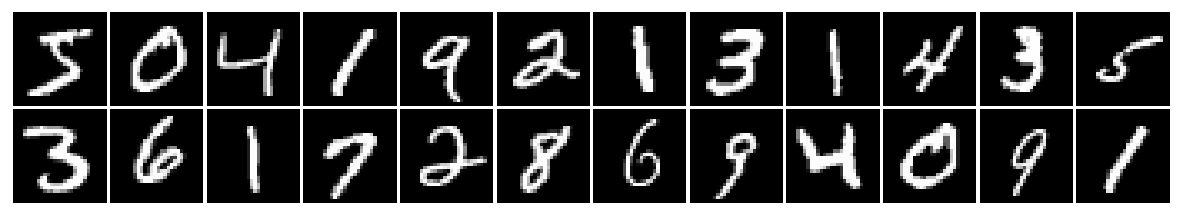

classes: [[5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5], [3, 6, 1, 7, 2, 8, 6, 9, 4, 0, 9, 1]]


In [5]:
n_samples = 24

# make_grid espera (N, canais, altura, largura): unsqueeze(dim=1) acrescenta o canal → (24, 1, 28, 28)
grid = torchvision.utils.make_grid(x_train[:n_samples].unsqueeze(dim=1), pad_value=1.0, padding=1, nrow=12)

plt.figure(figsize=(15, 3))
plt.imshow(grid.numpy().transpose(1, 2, 0))
plt.axis('off')
plt.show()
print('classes:', y_train[:n_samples].view(2, 12).tolist())

### Visualizando uma imagem com o matplotlib

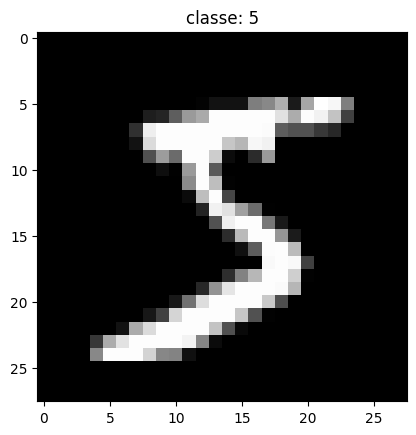

In [6]:
image  = x_train[0]
target = y_train[0]

plt.imshow(image.numpy(), cmap='gray')
plt.title(f'classe: {target.item()}')
plt.show()

## Modelo

In [20]:
model = nn.Linear(784, 10)  # 28*28 = 784 atributos de entrada e 10 neurônios na saída (um por dígito)

### Testando uma predição com poucas amostras

`nn.Linear` espera cada amostra como um vetor. `x.view(-1, 28*28)` muda o shape de (5, 28, 28) para (5, 784) sem copiar os dados; o `-1` deixa o PyTorch calcular essa dimensão (aqui, 5 amostras).

In [12]:
model(x_train[0].view(-1, 784))

tensor([[ 0.0991,  0.1537, -0.2098, -0.0753,  0.0583, -0.1490, -0.4113,  0.0951,
          0.2438, -0.2187]], grad_fn=<AddmmBackward0>)

In [13]:
xin = x_train[:5].view(-1, 28*28)
print('xin:', xin.shape)
score = model(xin)  # logits, shape (5, 10)
score

xin: torch.Size([5, 784])


tensor([[ 0.0991,  0.1537, -0.2098, -0.0753,  0.0583, -0.1490, -0.4113,  0.0951,
          0.2438, -0.2187],
        [-0.2016,  0.1073, -0.1494,  0.0880,  0.5348,  0.0917, -0.1303,  0.1279,
          0.2609, -0.1959],
        [ 0.0392, -0.1656,  0.0344, -0.0197, -0.2795, -0.2051, -0.1344, -0.2470,
          0.2223,  0.0481],
        [ 0.1172, -0.1830,  0.2082, -0.1191, -0.1486,  0.2275,  0.1422, -0.0542,
          0.1207, -0.0160],
        [ 0.2851, -0.1509, -0.0260, -0.0235, -0.1816,  0.2082, -0.1037,  0.1932,
          0.2190,  0.1537]], grad_fn=<AddmmBackward0>)

Os logits não são probabilidades. A softmax os transforma em probabilidades que somam 1 em cada linha; com os pesos iniciais aleatórios, todas as classes ficam perto de 0,1.

In [14]:
probs = F.softmax(score, dim=1)
print(probs.detach().numpy().round(3))  # .detach(): tensor sem histórico de gradientes, para converter em NumPy
print('soma de cada linha:', probs.sum(dim=1).detach())

[[0.113 0.119 0.083 0.095 0.108 0.088 0.068 0.113 0.131 0.082]
 [0.076 0.103 0.08  0.101 0.158 0.101 0.081 0.105 0.12  0.076]
 [0.11  0.09  0.11  0.104 0.08  0.086 0.093 0.083 0.132 0.111]
 [0.108 0.08  0.118 0.085 0.083 0.121 0.111 0.091 0.108 0.095]
 [0.124 0.08  0.091 0.091 0.078 0.115 0.084 0.113 0.116 0.109]]
soma de cada linha: tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


## Treinamento

### Inicialização dos hiperparâmetros, da função de custo e do otimizador

In [21]:
n_epochs = 100
lr = 0.5

# CrossEntropyLoss como função de custo: recebe os logits (sem softmax) e os índices das classes
criterion = nn.CrossEntropyLoss()

# Gradiente descendente
optimizer = torch.optim.SGD(model.parameters(), lr=lr)

### Laço de treinamento com validação

Em cada época:

1. **Treino**: forward com as 1000 imagens, custo, `zero_grad()`, `backward()` e `step()`. Com batch completo, uma época é uma única iteração.
2. **Validação**: forward com as imagens de validação dentro de `torch.no_grad()`. Medimos custo e acurácia, mas não calculamos gradientes nem atualizamos parâmetros.

A acurácia de treino é medida com as saídas calculadas antes do `step()` daquela época.

In [22]:
x_train_flat = x_train.view(-1, 28 * 28)  # (1000, 784)
x_val_flat = x_val.view(-1, 28 * 28)      # (1000, 784)

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for i in range(n_epochs):
    # Treino
    outputs = model(x_train_flat)       # logits (1000, 10)
    loss = criterion(outputs, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())
    _, predicts = torch.max(outputs, 1)
    train_accuracies.append((predicts == y_train).float().mean().item())

    # Validação: sem gradientes e sem atualizar parâmetros
    with torch.no_grad():
        outputs_val = model(x_val_flat)
        loss_val = criterion(outputs_val, y_val)
        val_losses.append(loss_val.item())

        _, predicts_val = torch.max(outputs_val, 1)
        val_accuracies.append((predicts_val == y_val).float().mean().item())

    print(f'Época {i}: custo treino {train_losses[-1]:.4f}, acurácia treino {train_accuracies[-1]:.4f}, '
      f'custo validação {val_losses[-1]:.4f}, acurácia validação {val_accuracies[-1]:.4f}')

Época 0: custo treino 2.3193, acurácia treino 0.0810, custo validação 1.9112, acurácia validação 0.5420
Época 1: custo treino 1.8090, acurácia treino 0.6110, custo validação 1.6161, acurácia validação 0.6850
Época 2: custo treino 1.4683, acurácia treino 0.7710, custo validação 1.4253, acurácia validação 0.6930
Época 3: custo treino 1.2455, acurácia treino 0.7800, custo validação 1.2867, acurácia validação 0.7120
Época 4: custo treino 1.0943, acurácia treino 0.8190, custo validação 1.1881, acurácia validação 0.7250
Época 5: custo treino 0.9862, acurácia treino 0.8260, custo validação 1.1130, acurácia validação 0.7420
Época 6: custo treino 0.9058, acurácia treino 0.8350, custo validação 1.0531, acurácia validação 0.7430
Época 7: custo treino 0.8434, acurácia treino 0.8370, custo validação 1.0058, acurácia validação 0.7540
Época 8: custo treino 0.7934, acurácia treino 0.8490, custo validação 0.9653, acurácia validação 0.7560
Época 9: custo treino 0.7522, acurácia treino 0.8560, custo vali

### Visualizando custo e acurácia durante o treinamento

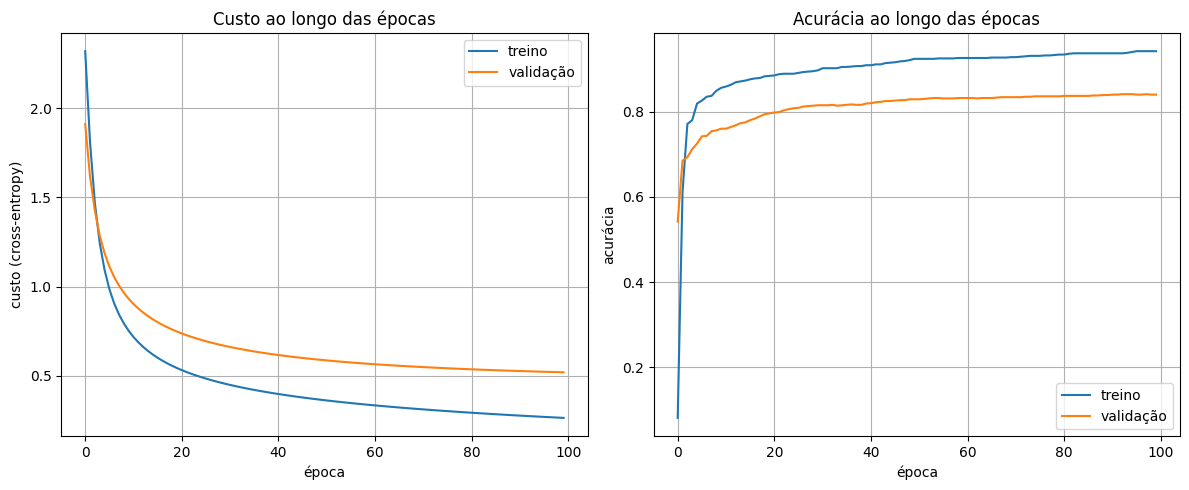

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='treino')
plt.plot(val_losses, label='validação')
plt.title('Custo ao longo das épocas')
plt.xlabel('época')
plt.ylabel('custo (cross-entropy)')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='treino')
plt.plot(val_accuracies, label='validação')
plt.title('Acurácia ao longo das épocas')
plt.xlabel('época')
plt.ylabel('acurácia')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

O custo e a acurácia de validação ficam piores que os de treino: o modelo foi ajustado às 1000 imagens de treino e é avaliado em imagens que não viu. Com poucas amostras para 7.850 parâmetros, essa diferença é esperada; o notebook 4.3 trata da generalização e do sobreajuste (overfitting). Repare também que as curvas de custo continuam descendo quando as de acurácia já quase não mudam.

## Avaliação

### Acurácia nos conjuntos de treinamento e de validação

Para avaliar usamos `model.eval()` e `torch.no_grad()`. Para `nn.Linear`, `model.eval()` não muda nada; é o padrão que usaremos sempre que avaliarmos um modelo.

In [24]:
def predict(model, input_data):
    with torch.no_grad():
        outputs = model(input_data)
    _, predicts = torch.max(outputs, 1)
    return predicts

model.eval()
y_pred = predict(model, x_train_flat)
y_pred_val = predict(model, x_val_flat)
print(f'Acurácia no treino:    {(y_pred == y_train).float().mean().item():.4f}')
print(f'Acurácia na validação: {(y_pred_val == y_val).float().mean().item():.4f}')

Acurácia no treino:    0.9420
Acurácia na validação: 0.8400


### Matriz de confusão com dados de treinamento e de validação

Linhas: classe prevista; colunas: classe real.

In [25]:
print('Matriz de confusão — treino:')
display(pd.crosstab(pd.Series(y_pred.numpy(), name='previsto'), pd.Series(y_train.numpy(), name='real')))
print('Matriz de confusão — validação:')
display(pd.crosstab(pd.Series(y_pred_val.numpy(), name='previsto'), pd.Series(y_val.numpy(), name='real')))

Matriz de confusão — treino:


real,0,1,2,3,4,5,6,7,8,9
previsto,,,,,,,,,,
0,96,0,1,0,0,0,1,0,0,2
1,0,111,1,0,0,0,2,3,1,0
2,0,0,91,1,0,1,0,1,2,1
3,0,0,0,87,0,2,0,0,0,0
4,0,0,1,0,102,2,1,1,0,3
5,0,2,0,2,0,82,0,0,2,1
6,1,0,1,1,2,2,90,0,0,0
7,0,1,1,1,0,0,0,111,0,3
8,0,2,2,0,0,1,0,0,82,0


Matriz de confusão — validação:


real,0,1,2,3,4,5,6,7,8,9
previsto,,,,,,,,,,
0,79,0,1,0,0,1,3,0,1,0
1,0,122,3,0,0,1,0,1,0,0
2,2,0,95,1,0,1,4,4,1,0
3,0,1,2,78,0,2,0,1,3,3
4,0,0,1,0,90,1,2,3,3,0
5,0,1,0,17,1,69,2,1,5,1
6,2,1,3,2,4,1,75,0,1,1
7,0,0,4,2,0,6,0,86,3,8
8,2,1,6,6,1,3,1,0,66,1


### Do logit à classe prevista, para uma imagem de validação

Para uma imagem, os 10 logits saem do modelo; a softmax os transforma em probabilidades; a classe prevista é a de maior valor (o mesmo índice nos dois casos).

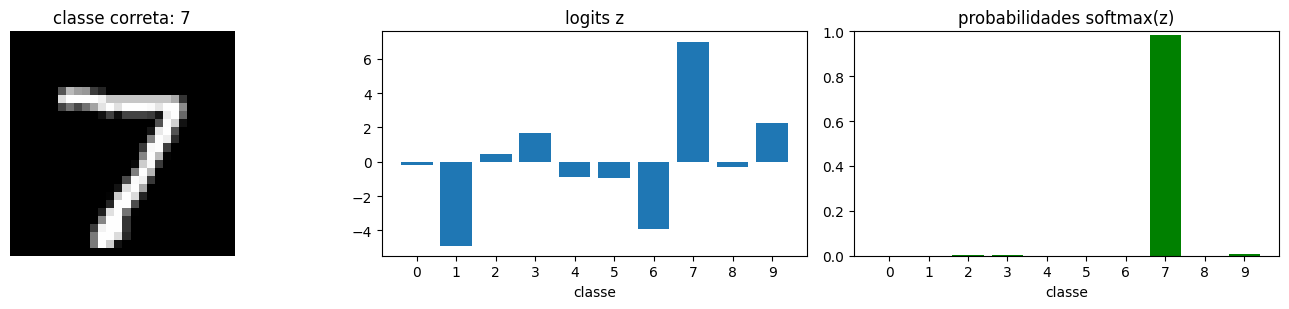

classe prevista: 7  probabilidade: 0.983


In [26]:
k = 0
with torch.no_grad():
    z = model(x_val_flat[k:k+1])[0]  # 10 logits
p = F.softmax(z, dim=0)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 3.2))
ax1.imshow(x_val[k].numpy(), cmap='gray'); ax1.set_title(f'classe correta: {y_val[k].item()}'); ax1.axis('off')
ax2.bar(range(10), z.numpy()); ax2.set_xticks(range(10)); ax2.set_title('logits z'); ax2.set_xlabel('classe')
ax3.bar(range(10), p.numpy(), color='g'); ax3.set_xticks(range(10)); ax3.set_ylim(0, 1)
ax3.set_title('probabilidades softmax(z)'); ax3.set_xlabel('classe')
plt.tight_layout()
plt.show()
print('classe prevista:', z.argmax().item(), ' probabilidade:', round(p.max().item(), 3))

## Visualizando a matriz de pesos treinados

A linha $k$ de $W$ tem 784 pesos, um por pixel, e o logit da classe $k$ é $z_k = \sum_j W_{k,j}\, x_j + b_k$. Reorganizada como imagem 28 × 28, a linha mostra quais pixels aumentam o logit da classe $k$ quando têm tinta (pesos positivos, claros) e quais o diminuem (pesos negativos, escuros).

weights: torch.Size([10, 784])
bias:    torch.Size([10])


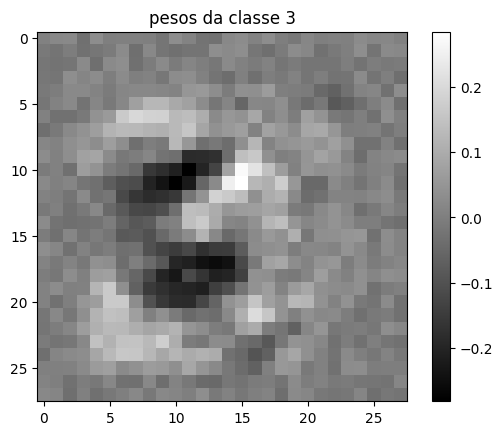

In [27]:
weights = model.state_dict()['weight']
print('weights:', weights.shape)

bias = model.state_dict()['bias']
print('bias:   ', bias.shape)

# Visualizando os pesos da classe 3
plt.imshow(weights[3, :].numpy().reshape((28, 28)), cmap='gray')
plt.title('pesos da classe 3')
plt.colorbar()
plt.show()

### Visualizando os pesos de todas as classes

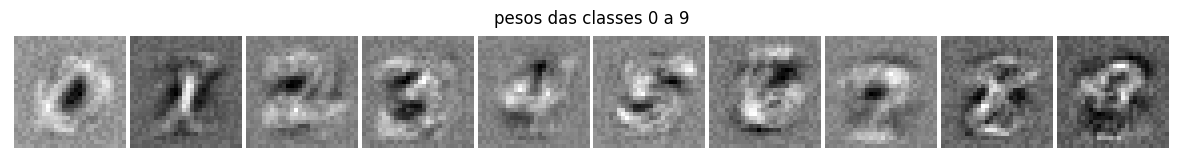

In [28]:
# cria um grid com as imagens; normalize=True ajusta cada imagem para a faixa [0, 1]
grid = torchvision.utils.make_grid(weights.view(-1, 1, 28, 28), normalize=True, scale_each=True,
                                   pad_value=1.0, padding=1, nrow=10)

plt.figure(figsize=(15, 2.5))
plt.imshow(grid.numpy().transpose(1, 2, 0))
plt.title('pesos das classes 0 a 9')
plt.axis('off')
plt.show()

### Diagrama da regressão softmax com visualização dos pesos W

![Diagrama: imagem de um dígito, os pesos de cada classe como imagem, os logits z0 a z9, softmax e argmax](https://raw.githubusercontent.com/vcasadei/images/master/RegressaoSoftmaxArgmaxNMIST.png)

## Exercícios

1. Escreva um laço de treinamento que, no final de cada época, imprima o número da época, o custo e a acurácia de treino. Use um modelo novo, para não continuar o treinamento do modelo acima.

In [ ]:
torch.manual_seed(0)
model_ex = nn.Linear(28*28, 10)
optimizer_ex = torch.optim.SGD(model_ex.parameters(), lr=lr)

for i in range(n_epochs):
    outputs = model_ex(x_train_flat)
    loss = criterion(outputs, y_train)
    optimizer_ex.zero_grad()
    loss.backward()
    optimizer_ex.step()

    # TODO: escreva sua solução aqui


2. Inclua no laço de treinamento a visualização dos gradientes referentes à classe do dígito 4 (`model.weight.grad[4]`, um vetor de 784 valores, visto como imagem 28 × 28) no final das épocas 1, 2, 5, 10, 50 e 100. Use outra vez um modelo novo. O que os gradientes mostram e como eles mudam ao longo do treinamento?

In [ ]:
torch.manual_seed(0)
model_ex = nn.Linear(28*28, 10)
optimizer_ex = torch.optim.SGD(model_ex.parameters(), lr=lr)
epochs_to_show = [1, 2, 5, 10, 50, 100]

# TODO: escreva sua solução aqui


*Escreva sua resposta aqui.*

### Perguntas

1. Qual é o shape da matriz de entrada da rede no treinamento?
2. Qual é o shape da saída da rede?
3. Qual é o número total de parâmetros da rede, incluindo o bias?

In [ ]:
# TODO: escreva sua solução aqui
1. (1000, 784) (28*28)
2. (1000, 10)
3. 784 * 10 + 10 = 7840 + 10 = 7850 parametros.

*Escreva sua resposta aqui.*

## Aprendizados

- A regressão softmax do Iris funciona sem mudanças para imagens: basta achatar cada imagem 28 × 28 num vetor de 784 atributos com `view(-1, 28*28)`.
- `nn.Linear(784, 10)` tem 7.850 parâmetros; cada linha de $W$ pode ser vista como uma imagem que indica quais pixels favorecem cada dígito.
- O gradiente da cross-entropy em relação aos logits é $p - \text{one-hot}(y)$: ele empurra a probabilidade da classe correta para 1 e a das outras para 0.
- O desempenho em validação é pior que no treino; acurácia de treino alta não garante acerto em imagens novas.
- A softmax que escolhe 1 entre 10 dígitos é a mesma que, num LLM, escolhe o próximo token entre dezenas de milhares de tokens do vocabulário.